In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data.csv")
print(df.shape)
df.head()

(11914, 16)


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Luxury,Compact,Convertible,28,18,3916,34500


In [26]:
print("Last 5 records:")
display(df.tail())
print("Random sample:")
display(df.sample(5))

Last 5 records:


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
11909,Acura,ZDX,2012,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Crossover,Hatchback,Luxury",Midsize,4dr Hatchback,23,16,204,46120
11910,Acura,ZDX,2012,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Crossover,Hatchback,Luxury",Midsize,4dr Hatchback,23,16,204,56670
11911,Acura,ZDX,2012,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Crossover,Hatchback,Luxury",Midsize,4dr Hatchback,23,16,204,50620
11912,Acura,ZDX,2013,premium unleaded (recommended),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Crossover,Hatchback,Luxury",Midsize,4dr Hatchback,23,16,204,50920
11913,Lincoln,Zephyr,2006,regular unleaded,221.0,6.0,AUTOMATIC,front wheel drive,4.0,Luxury,Midsize,Sedan,26,17,61,28995


Random sample:


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
9579,Chevrolet,Silverado 1500,2016,flex-fuel (unleaded/E85),285.0,6.0,AUTOMATIC,four wheel drive,4.0,Flex Fuel,Large,Extended Cab Pickup,22,17,1385,35100
3496,Dodge,Dart,2016,regular unleaded,184.0,4.0,MANUAL,front wheel drive,4.0,NaN,Midsize,Sedan,35,22,1851,19395
1171,Hyundai,Accent,2014,regular unleaded,138.0,4.0,AUTOMATIC,front wheel drive,4.0,Hatchback,Compact,4dr Hatchback,37,27,1439,17395
8292,Land Rover,Range Rover Sport,2016,diesel,254.0,6.0,AUTOMATIC,four wheel drive,4.0,"Diesel,Luxury",Midsize,4dr SUV,29,22,258,71450
11775,Cadillac,XTS,2016,regular unleaded,304.0,6.0,AUTOMATIC,front wheel drive,4.0,"Luxury,Performance",Large,Sedan,28,18,1624,49250


In [27]:
df.info()
print("Number of Rows:", df.shape[0])
print("Number of Columns:", df.shape[1])
print(df.columns.tolist())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11914 entries, 0 to 11913
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Make               11914 non-null  object 
 1   Model              11914 non-null  object 
 2   Year               11914 non-null  int64  
 3   Engine Fuel Type   11911 non-null  object 
 4   Engine HP          11845 non-null  float64
 5   Engine Cylinders   11884 non-null  float64
 6   Transmission Type  11914 non-null  object 
 7   Driven_Wheels      11914 non-null  object 
 8   Number of Doors    11908 non-null  float64
 9   Market Category    8172 non-null   object 
 10  Vehicle Size       11914 non-null  object 
 11  Vehicle Style      11914 non-null  object 
 12  highway MPG        11914 non-null  int64  
 13  city mpg           11914 non-null  int64  
 14  Popularity         11914 non-null  int64  
 15  MSRP               11914 non-null  int64  
dtypes: float64(3), int64(5

In [28]:
numerical_cols = df.select_dtypes(include=['number']).columns.tolist()
categorical_cols = df.select_dtypes(include=['object']).columns.tolist()
datetime_cols = df.select_dtypes(include=['datetime']).columns.tolist()

print("Numerical Columns:", numerical_cols)
print("\nCategorical Columns:", categorical_cols)
print("\nDate/Time Columns:", datetime_cols)

Numerical Columns: ['Year', 'Engine HP', 'Engine Cylinders', 'Number of Doors', 'highway MPG', 'city mpg', 'Popularity', 'MSRP']

Categorical Columns: ['Make', 'Model', 'Engine Fuel Type', 'Transmission Type', 'Driven_Wheels', 'Market Category', 'Vehicle Size', 'Vehicle Style']

Date/Time Columns: []


In [29]:
missing = df.isnull().sum()
missing_percent = (missing / len(df)) * 100
missing_df = pd.DataFrame({'Missing Values': missing, 'Percentage (%)': missing_percent.round(2)})
missing_df[missing_df['Missing Values'] > 0].sort_values('Missing Values', ascending=False)

,Missing Values,Percentage (%)
Market Category,3742,31.41
Engine HP,69,0.58
Engine Cylinders,30,0.25
Number of Doors,6,0.05
Engine Fuel Type,3,0.03


In [30]:
df['Market Category'] = df['Market Category'].fillna('Unknown')
df['Engine HP'] = df['Engine HP'].fillna(df['Engine HP'].median())
for col in ['Engine Cylinders', 'Number of Doors', 'Engine Fuel Type']:
    df[col] = df[col].fillna(df[col].mode()[0])

print("Total missing values after cleaning:", df.isnull().sum().sum())

Total missing values after cleaning: 0


In [31]:
print("Shape before removing duplicates:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
display(df[df.duplicated(keep=False)].sort_values(by=['Make', 'Model', 'Year']).head(6))

df = df.drop_duplicates().reset_index(drop=True)

print("\nShape after removing duplicates:", df.shape)
print("Duplicate rows remaining:", df.duplicated().sum())

Shape before removing duplicates: (11914, 16)
Duplicate rows: 715


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Market Category,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
8536,Acura,RL,2010,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Luxury,Performance",Midsize,Sedan,22,16,204,50450
8537,Acura,RL,2010,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Luxury,Performance",Midsize,Sedan,22,16,204,50450
8539,Acura,RL,2011,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Luxury,Performance",Midsize,Sedan,24,17,204,51350
8540,Acura,RL,2011,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Luxury,Performance",Midsize,Sedan,24,17,204,51350
8544,Acura,RL,2012,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Luxury,Performance",Midsize,Sedan,24,17,204,52350
8546,Acura,RL,2012,premium unleaded (required),300.0,6.0,AUTOMATIC,all wheel drive,4.0,"Luxury,Performance",Midsize,Sedan,24,17,204,52350



Shape after removing duplicates: (11199, 16)
Duplicate rows remaining: 0


In [32]:
print("Data types BEFORE:")
print(df.dtypes)

for col in ['Engine HP', 'Engine Cylinders', 'Number of Doors']:
    df[col] = df[col].astype(int)

print("\nData types AFTER:")
print(df.dtypes)

Data types BEFORE:
Make                  object
Model                 object
Year                   int64
Engine Fuel Type      object
Engine HP            float64
Engine Cylinders     float64
Transmission Type     object
Driven_Wheels         object
Number of Doors      float64
Market Category       object
Vehicle Size          object
Vehicle Style         object
highway MPG            int64
city mpg               int64
Popularity             int64
MSRP                   int64
dtype: object

Data types AFTER:
Make                 object
Model                object
Year                  int64
Engine Fuel Type     object
Engine HP             int64
Engine Cylinders      int64
Transmission Type    object
Driven_Wheels        object
Number of Doors       int64
Market Category      object
Vehicle Size         object
Vehicle Style        object
highway MPG           int64
city mpg              int64
Popularity            int64
MSRP                  int64
dtype: object


In [33]:
df = df.rename(columns={
    'Engine Fuel Type': 'Fuel_Type',
    'Engine HP': 'Engine_HP',
    'Engine Cylinders': 'Engine_Cylinders',
    'Transmission Type': 'Transmission_Type',
    'Number of Doors': 'Number_of_Doors',
    'Market Category': 'Market_Category',
    'Vehicle Size': 'Vehicle_Size',
    'Vehicle Style': 'Vehicle_Style',
    'highway MPG': 'Highway_MPG',
    'city mpg': 'City_MPG'
})
print(df.columns.tolist())
df.head()

['Make', 'Model', 'Year', 'Fuel_Type', 'Engine_HP', 'Engine_Cylinders', 'Transmission_Type', 'Driven_Wheels', 'Number_of_Doors', 'Market_Category', 'Vehicle_Size', 'Vehicle_Style', 'Highway_MPG', 'City_MPG', 'Popularity', 'MSRP']


,Make,Model,Year,Fuel_Type,Engine_HP,Engine_Cylinders,Transmission_Type,Driven_Wheels,Number_of_Doors,Market_Category,Vehicle_Size,Vehicle_Style,Highway_MPG,City_MPG,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335,6,MANUAL,rear wheel drive,2,"Factory Tuner,Luxury,High-Performance",Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300,6,MANUAL,rear wheel drive,2,"Luxury,Performance",Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300,6,MANUAL,rear wheel drive,2,"Luxury,High-Performance",Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230,6,MANUAL,rear wheel drive,2,"Luxury,Performance",Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230,6,MANUAL,rear wheel drive,2,Luxury,Compact,Convertible,28,18,3916,34500


In [34]:
print("Year range:", df['Year'].min(), "to", df['Year'].max())
print("Zero or negative MSRP:", (df['MSRP'] <= 0).sum())
print("MSRP below 5000:", (df['MSRP'] < 5000).sum())
print("Zero Engine_HP:", (df['Engine_HP'] <= 0).sum())
print("Zero Engine_Cylinders:", (df['Engine_Cylinders'] == 0).sum())
print("Number_of_Doors values:", sorted(df['Number_of_Doors'].unique()))
print("Highway_MPG max:", df['Highway_MPG'].max(), "| City_MPG max:", df['City_MPG'].max())
print("Zero or negative Popularity:", (df['Popularity'] <= 0).sum())
print("Transmission UNKNOWN count:", (df['Transmission_Type'] == 'UNKNOWN').sum())

Year range: 1990 to 2017
Zero or negative MSRP: 0
MSRP below 5000: 1322
Zero Engine_HP: 0
Zero Engine_Cylinders: 56
Number_of_Doors values: [np.int64(2), np.int64(3), np.int64(4)]
Highway_MPG max: 354 | City_MPG max: 137
Zero or negative Popularity: 0
Transmission UNKNOWN count: 12


In [35]:
print("Shape before:", df.shape)

# 1. Fix impossible Audi A6 2017 Highway_MPG (354)
bad = df['Highway_MPG'] == 354
same_car = (df['Make'] == 'Audi') & (df['Model'] == 'A6') & (df['Year'] == 2017) & (~bad)
df.loc[bad, 'Highway_MPG'] = int(df.loc[same_car, 'Highway_MPG'].median())

# 2. Replace UNKNOWN transmission with mode
mode_trans = df.loc[df['Transmission_Type'] != 'UNKNOWN', 'Transmission_Type'].mode()[0]
df['Transmission_Type'] = df['Transmission_Type'].replace('UNKNOWN', mode_trans)

# 3. Drop unrealistic MSRP (placeholder 2000 and used-market values below 5000)
df = df[df['MSRP'] >= 5000].reset_index(drop=True)

print("Shape after:", df.shape)
print("Minimum MSRP:", df['MSRP'].min())
print("Highway_MPG max (non-electric):", df[df['Fuel_Type'] != 'electric']['Highway_MPG'].max())
print("UNKNOWN transmission remaining:", (df['Transmission_Type'] == 'UNKNOWN').sum())

Shape before: (11199, 16)
Shape after: (9877, 16)
Minimum MSRP: 5035
Highway_MPG max (non-electric): 53
UNKNOWN transmission remaining: 0


In [36]:
print("Shape:", df.shape)
print("Total missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("\nData types:")
print(df.dtypes)
print("\nBasic statistics:")
display(df.describe())

df.to_csv("cleaned_data.csv", index=False)

Shape: (9877, 16)
Total missing values: 0
Duplicate rows: 0

Data types:
Make                 object
Model                object
Year                  int64
Fuel_Type            object
Engine_HP             int64
Engine_Cylinders      int64
Transmission_Type    object
Driven_Wheels        object
Number_of_Doors       int64
Market_Category      object
Vehicle_Size         object
Vehicle_Style        object
Highway_MPG           int64
City_MPG              int64
Popularity            int64
MSRP                  int64
dtype: object

Basic statistics:


,Year,Engine_HP,Engine_Cylinders,Number_of_Doors,Highway_MPG,City_MPG,Popularity,MSRP
count,9877.000000,9877.000000,9877.000000,9877.000000,9877.000000,9877.000000,9877.000000,9.877000e+03
mean,2012.797813,264.839931,5.684823,3.523337,26.996153,20.043637,1566.427356,4.722436e+04
std,4.613025,110.211603,1.835638,0.838393,8.684049,9.617282,1430.968681,6.368315e+04
min,1991.000000,66.000000,0.000000,2.000000,12.000000,7.000000,2.000000,5.035000e+03
25%,2010.000000,182.000000,4.000000,4.000000,22.000000,16.000000,549.000000,2.490500e+04
50%,2015.000000,252.000000,6.000000,4.000000,26.000000,18.000000,1385.000000,3.299000e+04
75%,2016.000000,310.000000,6.000000,4.000000,31.000000,22.000000,2009.000000,4.544500e+04
max,2017.000000,1001.000000,16.000000,4.000000,111.000000,137.000000,5657.000000,2.065902e+06


In [37]:
num_cols = ['Year', 'Engine_HP', 'Engine_Cylinders', 'Number_of_Doors',
            'Highway_MPG', 'City_MPG', 'Popularity', 'MSRP']

stats = pd.DataFrame({
    'Mean': df[num_cols].mean(),
    'Median': df[num_cols].median(),
    'Mode': df[num_cols].mode().iloc[0],
    'Min': df[num_cols].min(),
    'Max': df[num_cols].max(),
    'Range': df[num_cols].max() - df[num_cols].min(),
    'Std_Dev': df[num_cols].std(),
    'Variance': df[num_cols].var()
}).round(2)
display(stats)

print("\nMost common category in each column:")
for col in ['Make', 'Fuel_Type', 'Transmission_Type', 'Driven_Wheels', 'Vehicle_Size', 'Vehicle_Style']:
    print(col, "->", df[col].mode()[0])

,Mean,Median,Mode,Min,Max,Range,Std_Dev,Variance
Year,2012.80,2015.0,2016,1991,2017,26,4.61,2.128000e+01
Engine_HP,264.84,252.0,200,66,1001,935,110.21,1.214660e+04
Engine_Cylinders,5.68,6.0,4,0,16,16,1.84,3.370000e+00
Number_of_Doors,3.52,4.0,4,2,4,2,0.84,7.000000e-01
Highway_MPG,27.00,26.0,23,12,111,99,8.68,7.541000e+01
City_MPG,20.04,18.0,17,7,137,130,9.62,9.249000e+01
Popularity,1566.43,1385.0,1385,2,5657,5655,1430.97,2.047671e+06
MSRP,47224.36,32990.0,29995,5035,2065902,2060867,63683.15,4.055544e+09



Most common category in each column:
Make -> Chevrolet
Fuel_Type -> regular unleaded
Transmission_Type -> AUTOMATIC
Driven_Wheels -> front wheel drive
Vehicle_Size -> Midsize
Vehicle_Style -> Sedan


In [38]:
corr = df[num_cols].corr().round(2)
display(corr)
print("\nCorrelation of each variable with MSRP (strongest first):")
print(corr['MSRP'].drop('MSRP').sort_values(ascending=False))

,Year,Engine_HP,Engine_Cylinders,Number_of_Doors,Highway_MPG,City_MPG,Popularity,MSRP
Year,1.00,0.18,-0.12,0.14,0.27,0.20,0.13,0.04
Engine_HP,0.18,1.00,0.81,-0.23,-0.45,-0.40,0.04,0.64
Engine_Cylinders,-0.12,0.81,1.00,-0.18,-0.65,-0.58,0.02,0.57
Number_of_Doors,0.14,-0.23,-0.18,1.00,0.10,0.11,-0.04,-0.22
Highway_MPG,0.27,-0.45,-0.65,0.10,1.00,0.94,-0.01,-0.22
City_MPG,0.20,-0.40,-0.58,0.11,0.94,1.00,0.01,-0.19
Popularity,0.13,0.04,0.02,-0.04,-0.01,0.01,1.00,-0.06
MSRP,0.04,0.64,0.57,-0.22,-0.22,-0.19,-0.06,1.00



Correlation of each variable with MSRP (strongest first):
Engine_HP           0.64
Engine_Cylinders    0.57
Year                0.04
Popularity         -0.06
City_MPG           -0.19
Highway_MPG        -0.22
Number_of_Doors    -0.22
Name: MSRP, dtype: float64


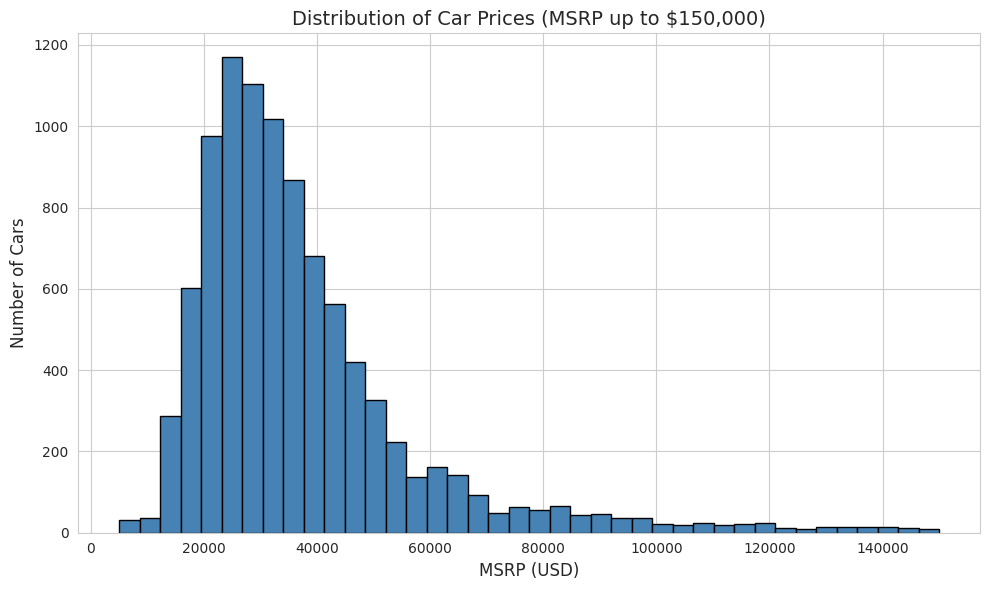

In [39]:
import os
os.makedirs("images", exist_ok=True)
sns.set_style("whitegrid")

plt.figure(figsize=(10, 6))
plt.hist(df[df['MSRP'] <= 150000]['MSRP'], bins=40, color='steelblue', edgecolor='black')
plt.title("Distribution of Car Prices (MSRP up to $150,000)", fontsize=14)
plt.xlabel("MSRP (USD)", fontsize=12)
plt.ylabel("Number of Cars", fontsize=12)
plt.tight_layout()
plt.savefig("images/visualization_01.png", dpi=150)
plt.show()

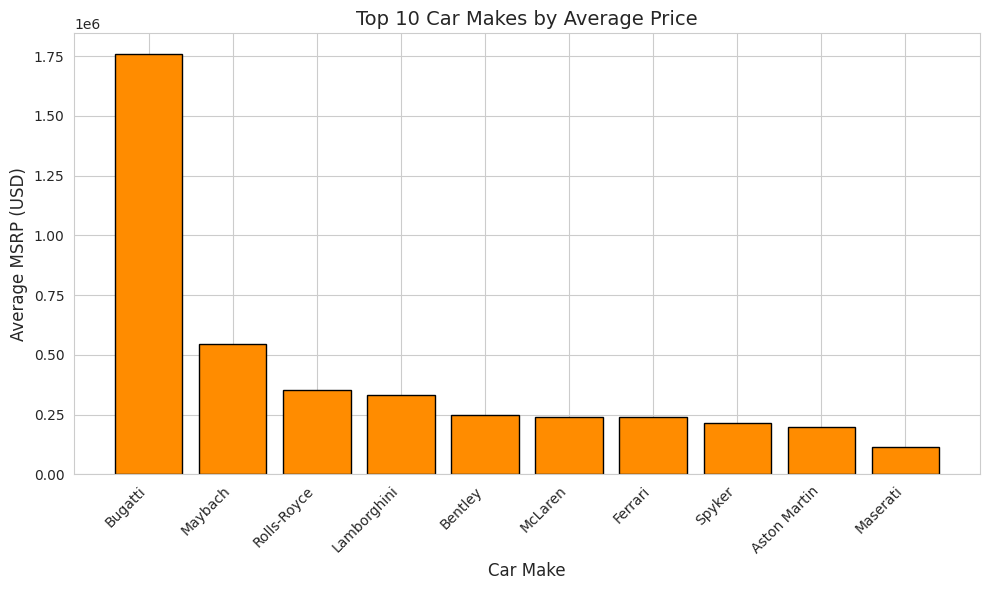

In [40]:
top_makes = df.groupby('Make')['MSRP'].mean().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
plt.bar(top_makes.index, top_makes.values, color='darkorange', edgecolor='black')
plt.title("Top 10 Car Makes by Average Price", fontsize=14)
plt.xlabel("Car Make", fontsize=12)
plt.ylabel("Average MSRP (USD)", fontsize=12)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.savefig("images/visualization_02.png", dpi=150)
plt.show()

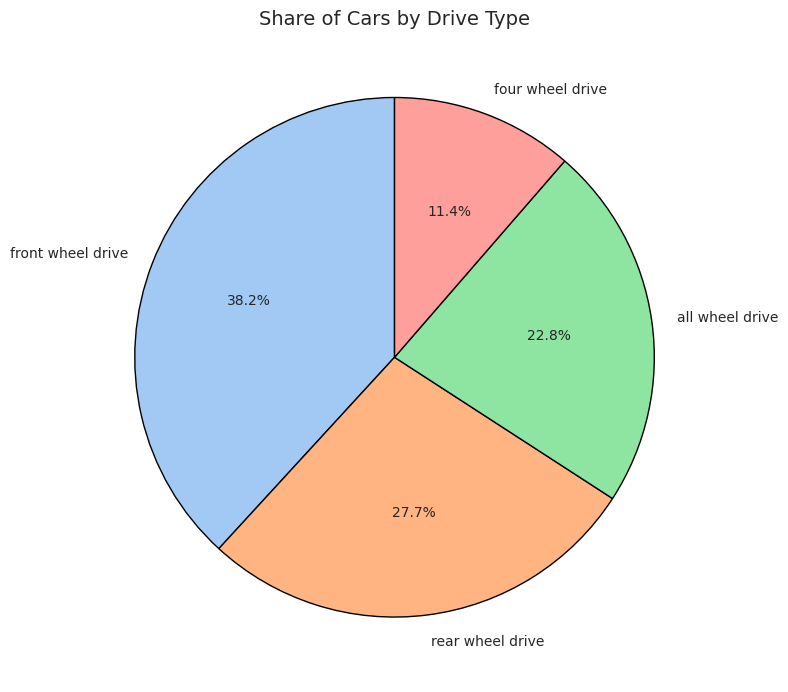

In [41]:
# Graph 3: Pie chart - share of cars by drive type
drive_counts = df['Driven_Wheels'].value_counts()

plt.figure(figsize=(8, 8))
plt.pie(drive_counts.values, labels=drive_counts.index, autopct='%1.1f%%',
        startangle=90, colors=sns.color_palette('pastel'),
        wedgeprops={'edgecolor': 'black'})
plt.title("Share of Cars by Drive Type", fontsize=14)
plt.tight_layout()
plt.savefig("images/visualization_03.png", dpi=150)
plt.show()

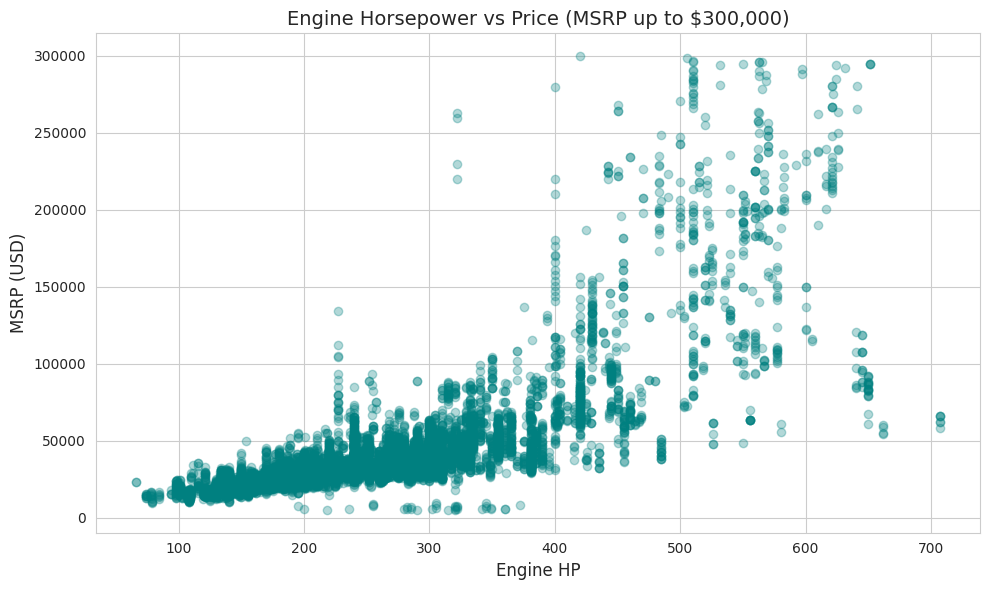

In [42]:
# Graph 4: Scatter plot - Engine HP vs MSRP (MSRP up to 300,000 for readability)
subset = df[df['MSRP'] <= 300000]

plt.figure(figsize=(10, 6))
plt.scatter(subset['Engine_HP'], subset['MSRP'], alpha=0.3, color='teal')
plt.title("Engine Horsepower vs Price (MSRP up to $300,000)", fontsize=14)
plt.xlabel("Engine HP", fontsize=12)
plt.ylabel("MSRP (USD)", fontsize=12)
plt.tight_layout()
plt.savefig("images/visualization_04.png", dpi=150)
plt.show()

Cars before 2001: 46


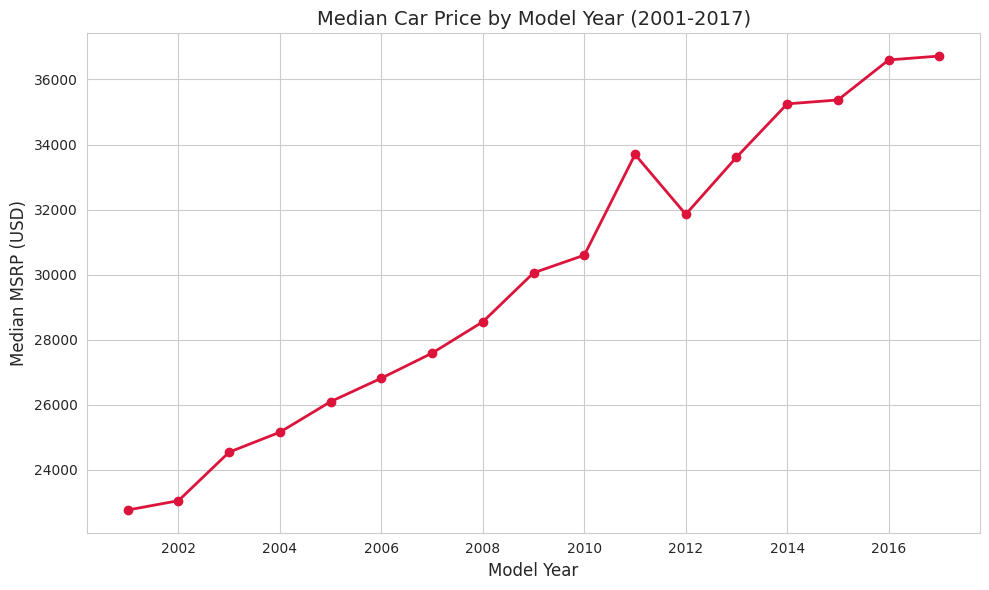

In [43]:
# Graph 5: Line chart - Median MSRP by model year (2001 onwards)
print("Cars before 2001:", (df['Year'] < 2001).sum())

yearly = df[df['Year'] >= 2001].groupby('Year')['MSRP'].median()

plt.figure(figsize=(10, 6))
plt.plot(yearly.index, yearly.values, marker='o', color='crimson', linewidth=2)
plt.title("Median Car Price by Model Year (2001-2017)", fontsize=14)
plt.xlabel("Model Year", fontsize=12)
plt.ylabel("Median MSRP (USD)", fontsize=12)
plt.grid(True)
plt.tight_layout()
plt.savefig("images/visualization_05.png", dpi=150)
plt.show()

/tmp/ipykernel_877/1247065372.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='Vehicle_Size', y='MSRP', data=df[df['MSRP'] <= 150000],


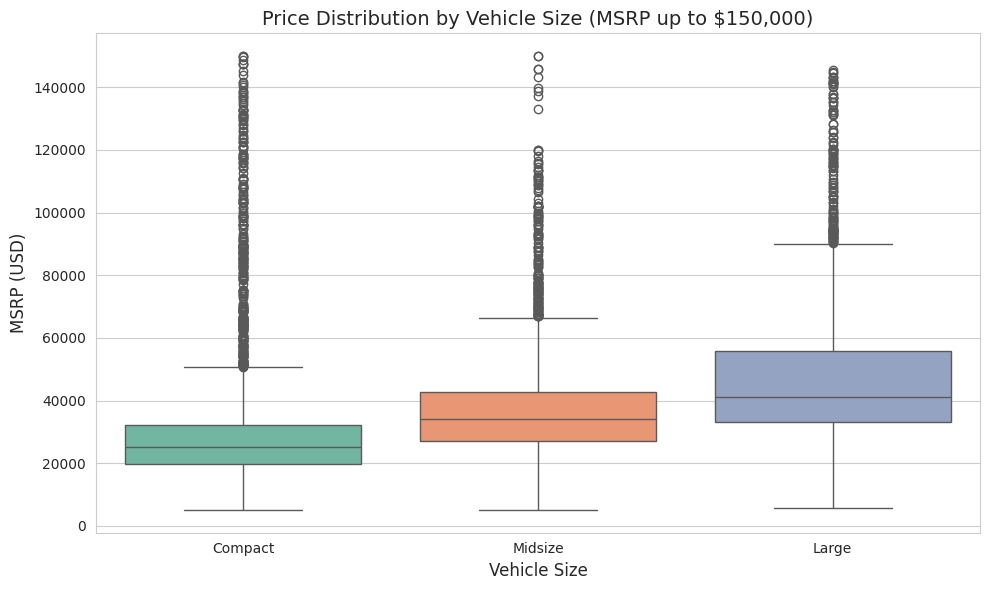

In [44]:
# Graph 6: Box plot - MSRP by vehicle size (limited to 150,000 for readability)
plt.figure(figsize=(10, 6))
sns.boxplot(x='Vehicle_Size', y='MSRP', data=df[df['MSRP'] <= 150000],
            order=['Compact', 'Midsize', 'Large'], palette='Set2')
plt.title("Price Distribution by Vehicle Size (MSRP up to $150,000)", fontsize=14)
plt.xlabel("Vehicle Size", fontsize=12)
plt.ylabel("MSRP (USD)", fontsize=12)
plt.tight_layout()
plt.savefig("images/visualization_06.png", dpi=150)
plt.show()

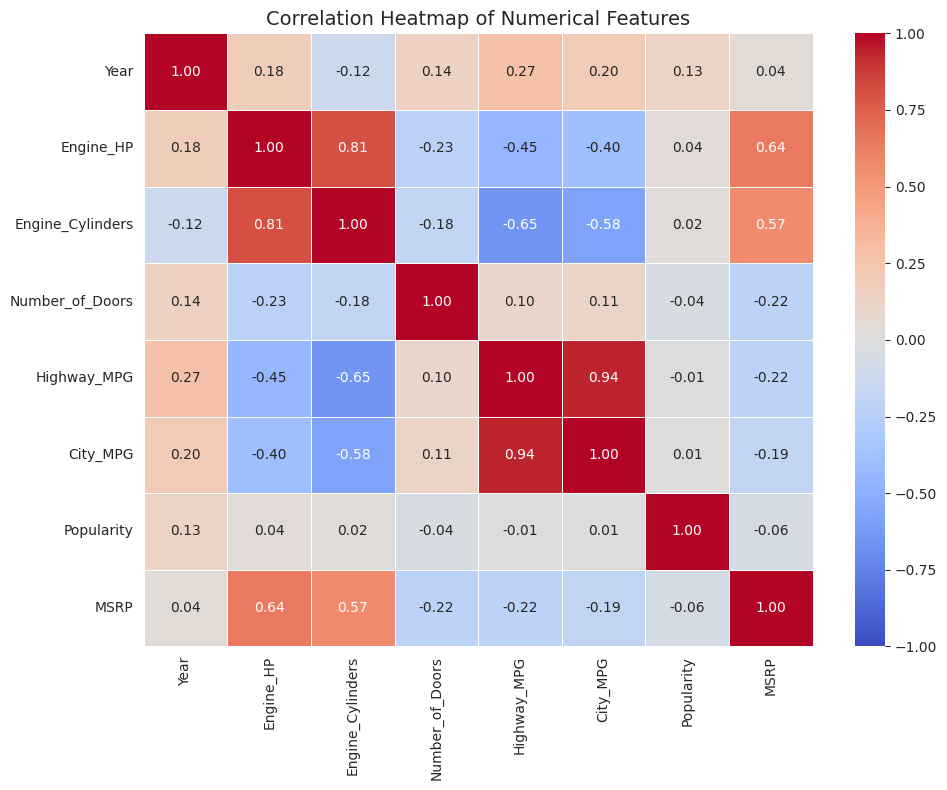

In [45]:
# Graph 7: Correlation heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df[num_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f',
            linewidths=0.5, vmin=-1, vmax=1)
plt.title("Correlation Heatmap of Numerical Features", fontsize=14)
plt.tight_layout()
plt.savefig("images/visualization_07.png", dpi=150)
plt.show()

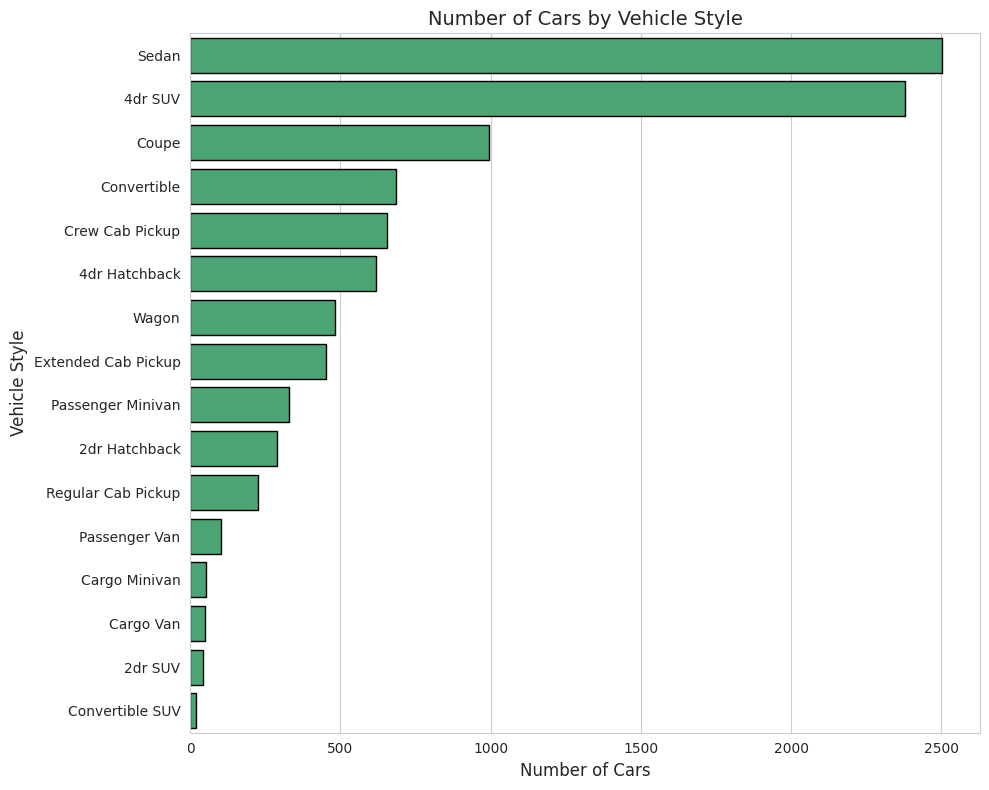

In [46]:
# Graph 8: Count plot - number of cars by vehicle style
plt.figure(figsize=(10, 8))
sns.countplot(y='Vehicle_Style', data=df,
              order=df['Vehicle_Style'].value_counts().index,
              color='mediumseagreen', edgecolor='black')
plt.title("Number of Cars by Vehicle Style", fontsize=14)
plt.xlabel("Number of Cars", fontsize=12)
plt.ylabel("Vehicle Style", fontsize=12)
plt.tight_layout()
plt.savefig("images/visualization_08.png", dpi=150)
plt.show()

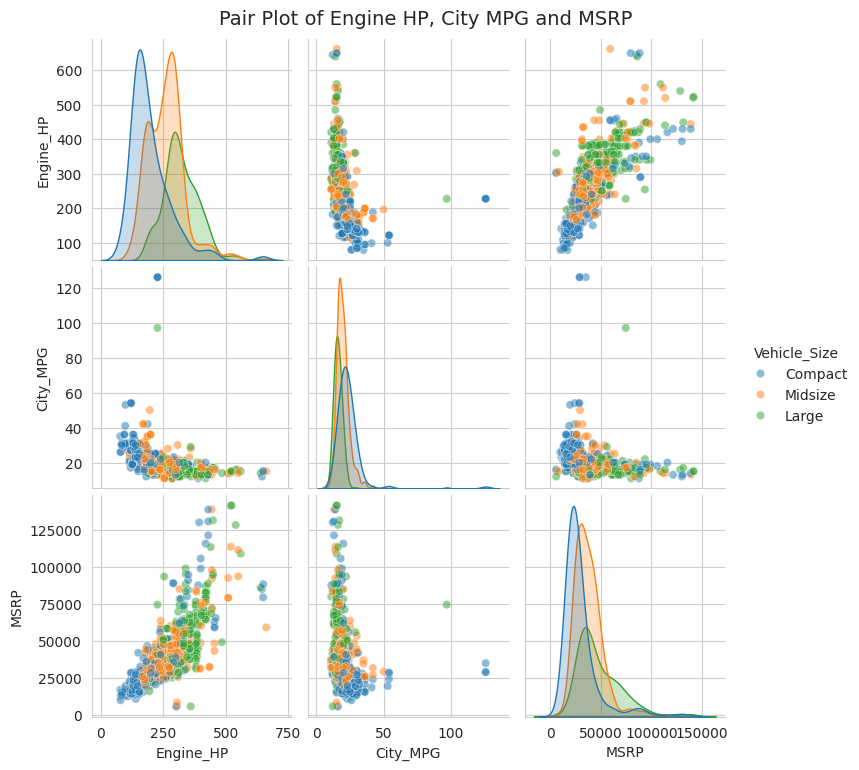

In [47]:
# Graph 9: Pair plot (random sample of 1000 rows for speed)
pair_cols = ['Engine_HP', 'City_MPG', 'MSRP', 'Vehicle_Size']
sample = df[df['MSRP'] <= 150000].sample(1000, random_state=42)

g = sns.pairplot(sample[pair_cols], hue='Vehicle_Size',
                 hue_order=['Compact', 'Midsize', 'Large'],
                 plot_kws={'alpha': 0.5})
g.fig.suptitle("Pair Plot of Engine HP, City MPG and MSRP", y=1.02, fontsize=14)
g.savefig("images/visualization_09.png", dpi=150)
plt.show()

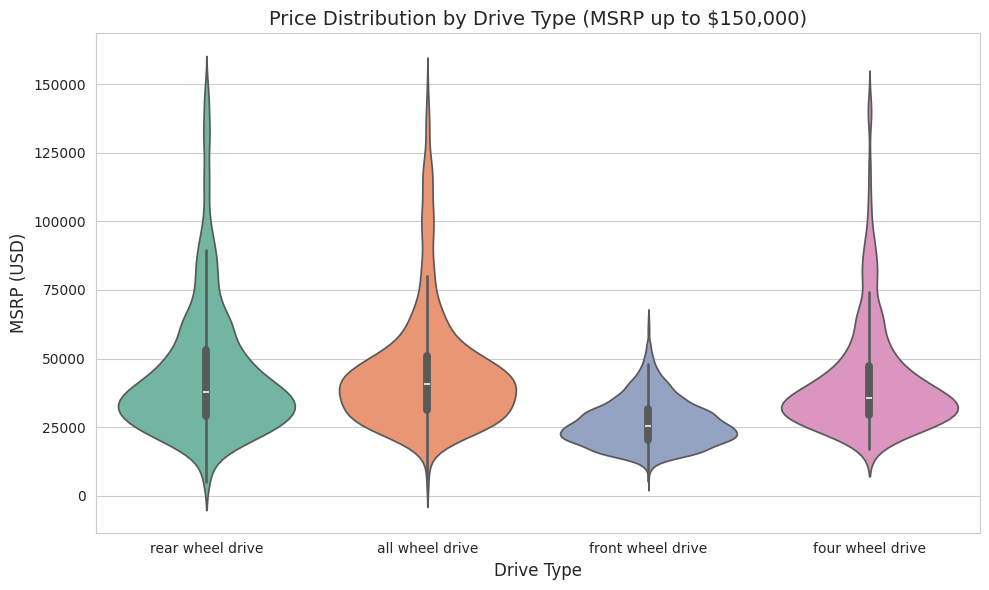

In [48]:
# Graph 10: Violin plot - MSRP by drive type (MSRP up to 150,000)
plt.figure(figsize=(10, 6))
sns.violinplot(x='Driven_Wheels', y='MSRP', hue='Driven_Wheels',
               data=df[df['MSRP'] <= 150000], palette='Set2', legend=False)
plt.title("Price Distribution by Drive Type (MSRP up to $150,000)", fontsize=14)
plt.xlabel("Drive Type", fontsize=12)
plt.ylabel("MSRP (USD)", fontsize=12)
plt.tight_layout()
plt.savefig("images/visualization_10.png", dpi=150)
plt.show()

In [49]:
# Numbers for Part 5 insights
print("Top 5 makes by AVERAGE price (with number of cars):")
g = df.groupby('Make')['MSRP'].agg(['mean', 'count']).round(0)
print(g.sort_values('mean', ascending=False).head(5))

print("\nCheapest 5 makes by average price (makes with 20+ cars):")
print(g[g['count'] >= 20].sort_values('mean').head(5))

print("\nMost common 5 makes:")
print(df['Make'].value_counts().head(5))

print("\nMedian MSRP by Vehicle Size:")
print(df.groupby('Vehicle_Size')['MSRP'].median())

print("\nMedian MSRP by Drive Type:")
print(df.groupby('Driven_Wheels')['MSRP'].median())

print("\nMedian MSRP by Fuel Type (types with 50+ cars):")
f = df.groupby('Fuel_Type')['MSRP'].agg(['median', 'count'])
print(f[f['count'] >= 50].sort_values('median', ascending=False))

print("\nAverage Highway MPG by Engine Cylinders (non-electric):")
print(df[df['Fuel_Type'] != 'electric'].groupby('Engine_Cylinders')['Highway_MPG'].mean().round(1))

q1, q3 = df['MSRP'].quantile([0.25, 0.75])
upper = q3 + 1.5 * (q3 - q1)
print("\nMSRP outlier limit:", round(upper), "| cars above it:", (df['MSRP'] > upper).sum())

print("\nVariation (Std Dev / Mean), higher means more spread:")
print((df[num_cols].std() / df[num_cols].mean()).round(2).sort_values(ascending=False))

ev = df[df['Fuel_Type'] == 'electric']
print("\nElectric cars:", len(ev), "| median MSRP:", ev['MSRP'].median())

Top 5 makes by AVERAGE price (with number of cars):
                  mean  count
Make                         
Bugatti      1757224.0      3
Maybach       546222.0     16
Rolls-Royce   351131.0     31
Lamborghini   331567.0     52
Bentley       247169.0     74

Cheapest 5 makes by average price (makes with 20+ cars):
               mean  count
Make                      
Suzuki      19910.0    306
Scion       19932.0     60
FIAT        22670.0     62
Mitsubishi  24050.0    182
Mazda       24132.0    341

Most common 5 makes:
Make
Chevrolet     961
Ford          697
Toyota        646
Volkswagen    549
Nissan        486
Name: count, dtype: int64

Median MSRP by Vehicle Size:
Vehicle_Size
Compact    25595.0
Large      42550.0
Midsize    34590.0
Name: MSRP, dtype: float64

Median MSRP by Drive Type:
Driven_Wheels
all wheel drive      41800.0
four wheel drive     35700.0
front wheel drive    25230.0
rear wheel drive     39850.0
Name: MSRP, dtype: float64

Median MSRP by Fuel Type (types wit

## Part 5: Key Insights and Findings

1. **Typical price vs. average price:** The median car price is \$32,990, while the mean is \$47,224. A small number of extremely expensive cars (maximum \$2,065,902) pull the average up, so the median describes a typical car better than the mean.

2. **Most expensive brands:** Bugatti has the highest average price (\$1,757,224), followed by Maybach (\$546,222), Rolls-Royce (\$351,131), Lamborghini (\$331,567) and Bentley (\$247,169). Bugatti has only 3 cars in the dataset, so its average is based on very few records.

3. **Most affordable brands (brands with 20+ cars):** Suzuki (\$19,910), Scion (\$19,932) and FIAT (\$22,670) have the lowest average prices. Suzuki is about 40% below the overall median price.

4. **Most common brand:** Chevrolet appears most often (961 cars, about 9.7% of the cleaned data), followed by Ford (697) and Toyota (646).

5. **Strongest relationships with price:** Engine horsepower (correlation 0.64) and number of cylinders (0.57) have the strongest positive relationships with MSRP. Popularity (-0.06) and model year (0.04) have almost no relationship with price.

6. **Vehicle size:** Median price rises with size: Compact \$25,595, Midsize \$34,590 and Large \$42,550. Large vehicles cost about 66% more than compact ones.

7. **Drive type:** Front wheel drive cars are the cheapest (median \$25,230) and the most common (38.2% of cars). All wheel drive (\$41,800) and rear wheel drive (\$39,850) cars cost much more.

8. **Fuel type:** Regular unleaded cars are the most common (5,369 of 9,877 cars, about 54%) and the cheapest (median \$26,675). Cars that require premium unleaded fuel have a median price of \$61,025, more than double. The highest median (\$142,995) belongs to flex-fuel premium cars, but there are only 53 of them.

9. **Fuel economy trade-off:** For non-electric cars, average highway MPG falls steadily as the number of cylinders grows: 31.9 MPG for 4 cylinders, 24.3 for 6, 20.4 for 8 and 14.0 for 16. More powerful engines use more fuel.

10. **Outliers and variation:** 939 cars (about 9.5%) are priced above the outlier limit of \$76,255. MSRP shows the highest variation of all numerical columns (standard deviation is 1.35 times the mean), followed by Popularity (0.91).

11. **Unexpected finding, electric cars:** The 66 electric cars have a median price of \$36,285, only slightly above the overall median (\$32,990) and far below premium-fuel cars (\$61,025). Their MPG values (MPGe) exceed 100, which is why the MPG columns have such large maximums.

## Part 6: Final Conclusion

In this project I analyzed the "Car Features and MSRP" dataset from Kaggle, which contains 11,914 car records with 16 features such as make, model, year, engine power, fuel type, fuel economy and price (MSRP). The purpose was to understand what drives car prices and to practice a complete data analysis workflow. During cleaning, I filled missing values (the median for Engine HP, the mode for cylinders, doors and fuel type, and "Unknown" for Market Category, which was missing in 31% of rows), removed 715 duplicate rows, converted three columns from float to integer, and renamed the columns to a consistent style. I also removed 1,322 rows whose MSRP was unrealistic (748 rows with a repeated placeholder price of \$2,000 and 574 older cars priced below \$5,000, which were not real launch prices), corrected one impossible fuel economy value (354 MPG) and replaced 12 "UNKNOWN" transmission entries. The final dataset has 9,877 rows and 16 columns, with no missing values and no duplicates. I then calculated descriptive statistics and correlations and created 10 visualizations (histogram, bar chart, pie chart, scatter plot, line chart, box plot, heatmap, count plot, pair plot and violin plot).

The most important findings are that the median price (\$32,990) is much lower than the mean (\$47,224) because a few extremely expensive cars skew the data, and that engine horsepower (correlation 0.64) and number of cylinders (0.57) are the strongest drivers of price, while popularity and model year have almost no relationship with it. Larger vehicles, rear and all wheel drive cars, and cars requiring premium fuel are more expensive, and more powerful engines use more fuel (highway MPG drops from 31.9 for 4 cylinders to 14.0 for 16). Through this project I learned how to detect and justify data cleaning decisions, why the median is often better than the mean when outliers are present, and how to turn charts into clear explanations. The analysis could help buyers compare cars by price and fuel cost, and help sellers understand which features are linked to higher prices, and it forms a good base for future machine learning tasks such as price prediction.